# D1_06 고장 설비는 무엇이 다른가?

> **오늘 질문:** 차트 3장으로 고장의 특징을 설명할 수 있을까?

Seaborn 차트는 대부분 `data`, `x`, `y`, `hue` 네 가지 인자로 그립니다.

| 표시 | 의미 |
|---|---|
| 📋 제공 | 코드가 들어 있습니다. 실행만 하세요 |
| ✍️ 입력 | 설명을 보고 직접 입력하세요 |
| 💬 해석 | 결과를 보고 답을 적어 보세요 |

## 0. 준비 📋

In [1]:
%matplotlib inline
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 5교시에서 결측·중복을 정리한 것과 같은 정제 완료 테이블
df = pd.read_parquet("../../data/factory_table.parquet")
equip_order = sorted(df["equip_id"].unique())   # 막대를 MC-01 ~ MC-10 순서로

In [2]:
df

,record_id,timestamp,equip_id,line,product_id,grade,air_temp,process_temp,rpm,torque,tool_wear,vibration,failure,twf,hdf,pwf,osf,rnf
0,1,2025-01-01 00:00:00,MC-08,L2,M14860,M,25.0,35.5,1551,42.8,0,1.84,0,0,0,0,0,0
1,2,2025-01-01 00:14:24,MC-08,L2,L47181,L,25.1,35.6,1408,46.3,3,2.20,0,0,0,0,0,0
2,3,2025-01-01 00:28:48,MC-03,L1,L47182,L,25.0,35.4,1498,49.4,5,1.86,0,0,0,0,0,0
3,4,2025-01-01 00:43:12,MC-01,L1,L47183,L,25.1,35.5,1433,39.5,7,2.51,0,0,0,0,0,0
4,5,2025-01-01 00:57:36,MC-04,L1,L47184,L,25.1,35.6,1408,40.0,9,2.05,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,2025-04-10 22:48:00,MC-09,L2,M24855,M,25.7,35.2,1604,29.5,14,2.35,0,0,0,0,0,0
9996,9997,2025-04-10 23:02:24,MC-06,L2,H39410,H,25.8,35.2,1632,31.8,17,2.16,0,0,0,0,0,0
9997,9998,2025-04-10 23:16:48,MC-09,L2,M24857,M,25.9,35.5,1645,33.4,22,2.44,0,0,0,0,0,0
9998,9999,2025-04-10 23:31:12,MC-07,L2,H39412,H,25.9,35.6,1408,48.5,25,2.15,0,0,0,0,0,0


In [4]:
df['equip_id'].unique()

array(['MC-08', 'MC-03', 'MC-01', 'MC-04', 'MC-02', 'MC-10', 'MC-06',
       'MC-07', 'MC-09', 'MC-05'], dtype=object)

In [5]:
sorted( df['equip_id'].unique() )

['MC-01',
 'MC-02',
 'MC-03',
 'MC-04',
 'MC-05',
 'MC-06',
 'MC-07',
 'MC-08',
 'MC-09',
 'MC-10']

## 1. 정상 vs 고장: 토크 분포 ✍️

박스플롯으로 정상(0)과 고장(1)의 토크를 비교합니다.

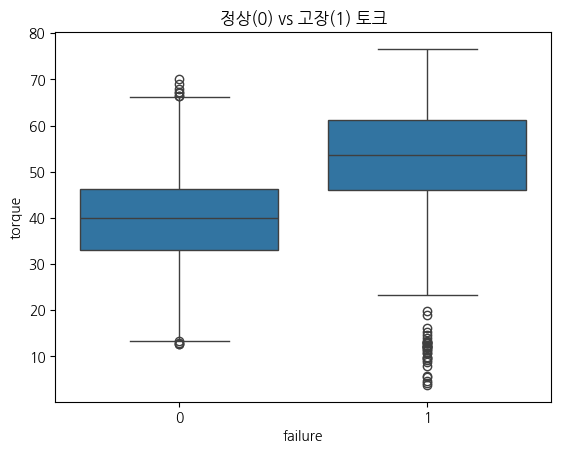

In [13]:
# 힌트: sns.boxplot(data=df, x="그룹 컬럼", y="값 컬럼")
sns.boxplot(data=df, x='failure', y='torque')
plt.title("정상(0) vs 고장(1) 토크")
plt.savefig('pic01.png')
plt.show()

`y`만 `tool_wear`로 바꿔 공구 마모도 비교해 보세요.

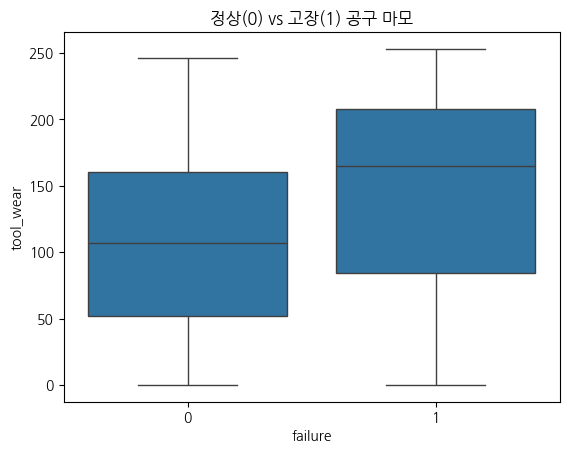

In [9]:
sns.boxplot(data=df, x='failure', y='tool_wear')
plt.title("정상(0) vs 고장(1) 공구 마모")
plt.show()

## 2. 설비별 고장률 ✍️

`failure`는 0과 1이므로 막대의 높이(평균)가 곧 고장률입니다. `order`는 막대 순서, `errorbar=None`은 오차 막대를 끕니다.

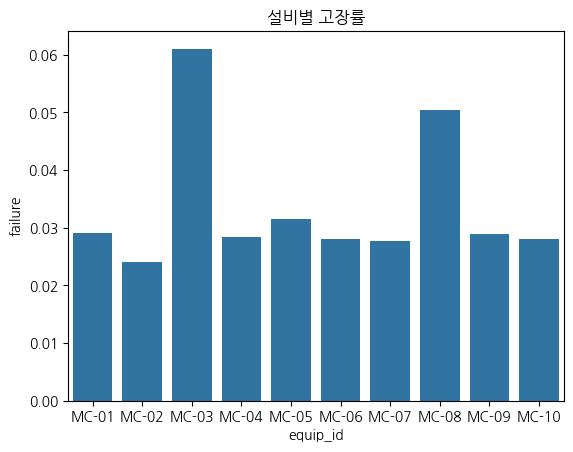

In [12]:
# 힌트: sns.barplot(data=df, x="equip_id", y="failure", order=equip_order, errorbar=None)
sns.barplot(data=df, x='equip_id', y='failure', order=equip_order, errorbar=None)
plt.title("설비별 고장률")
plt.show()

## 3. 센서 간 관계: 회전수와 토크 ✍️

`hue`에 고장 여부를 넣으면 고장이 어디에 모여 있는지 색으로 드러납니다.

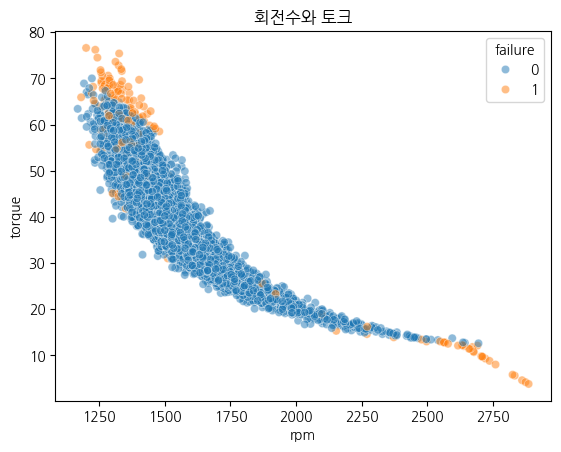

In [14]:
# 힌트: sns.scatterplot(data=df, x=..., y=..., hue="failure", alpha=0.5)
sns.scatterplot(data=df, x='rpm', y='torque', hue='failure', alpha=0.5)
plt.title("회전수와 토크")
plt.show()

**Q1.** 고장(주황 점)은 산점도의 어디에 모여 있나요?

> 답:


## 4. 센서 간 상관 히트맵 📋

In [17]:
sensors = ["air_temp", "process_temp", "rpm", "torque", "tool_wear", "vibration", "failure"]
df[sensors].corr()

,air_temp,process_temp,rpm,torque,tool_wear,vibration,failure
air_temp,1.000000,0.876022,0.022707,-0.013839,0.013304,0.015478,0.082204
process_temp,0.876022,1.000000,0.019507,-0.014182,0.013822,0.011253,0.035839
rpm,0.022707,0.019507,1.000000,-0.875027,0.000223,-0.013795,-0.044188
torque,-0.013839,-0.014182,-0.875027,1.000000,-0.003093,0.044121,0.191321
tool_wear,0.013304,0.013822,0.000223,-0.003093,1.000000,0.022430,0.105448
vibration,0.015478,0.011253,-0.013795,0.044121,0.022430,1.000000,0.209097
failure,0.082204,0.035839,-0.044188,0.191321,0.105448,0.209097,1.000000


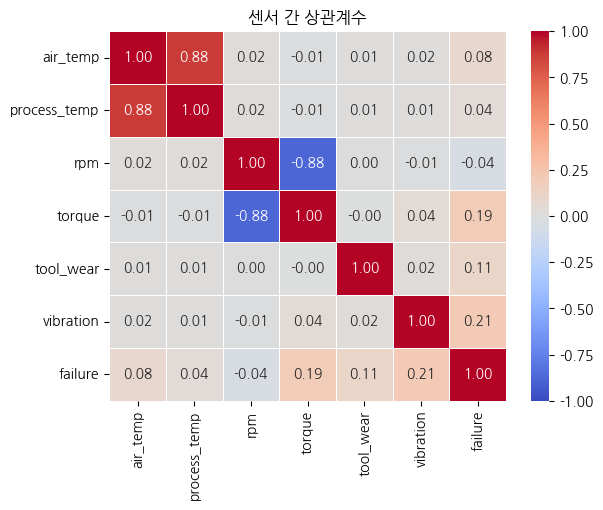

In [18]:
sensors = ["air_temp", "process_temp", "rpm", "torque", "tool_wear", "vibration", "failure"]
sns.heatmap(df[sensors].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("센서 간 상관계수")
plt.show()

## 5. 설명용 차트로 다듬기 ✍️

2번 차트를 보고서용으로 다듬습니다.
- **제목에 결론**을 씁니다.
- **강조색은 하나만**: 오래된 설비(MC-03, MC-08)만 색을 칠합니다.

> 변수 이름: `old` (오래된 설비 여부 컬럼)

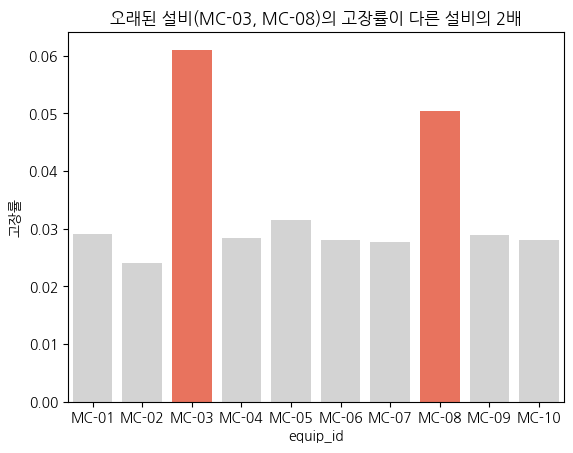

In [21]:
# 힌트: df["컬럼"].isin([값1, 값2]), palette=["lightgray", "tomato"]
df1 = df.copy()
df1['old'] = df1['equip_id'].isin( ['MC-03', 'MC-08'] )
sns.barplot(data=df1, x='equip_id', y='failure', order=equip_order, hue="old",
           palette=['lightgray','tomato'], errorbar=None, legend=False)
plt.title("오래된 설비(MC-03, MC-08)의 고장률이 다른 설비의 2배")
plt.ylabel("고장률")
plt.show()

## 정리 💬

**Q2.** 오늘 그린 차트 중 3장을 골라 "고장 설비는 무엇이 다른가?"를 세 문장으로 설명해 보세요.

> 답:
